In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (20640, 9)

First five rows:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [3]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 8)
Target shape: (20640,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 16512
Testing samples: 4128


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [6]:
knn = KNeighborsRegressor(
    n_neighbors=5,
    weights="uniform",
    metric="euclidean"
)

knn.fit(X_train_scaled, y_train)

print("KNN Regression model trained successfully.")

KNN Regression model trained successfully.


In [7]:
y_pred = knn.predict(X_test_scaled)

results = pd.DataFrame({
    "Actual Price ($100,000s)": y_test.values,
    "Predicted Price ($100,000s)": y_pred
})

display(results.head(10))

,"Actual Price ($100,000s)","Predicted Price ($100,000s)"
0,0.47700,0.498800
1,0.45800,0.764600
2,5.00001,4.750006
3,2.18600,2.876600
4,2.78000,2.726200
5,1.58700,1.778600
6,1.98200,2.718200
7,1.57500,1.924600
8,3.40000,2.031400
9,4.46600,4.955608


In [8]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("----------------")
print(f"MAE:  ${mae * 100000:,.2f}")
print(f"MSE:  {mse:.4f} (target units squared)")
print(f"RMSE: ${rmse * 100000:,.2f}")
print(f"R² Score: {r2:.4f}")

Model Evaluation
----------------
MAE:  $44,615.35
MSE:  0.4324 (target units squared)
RMSE: $65,758.77
R² Score: 0.6700


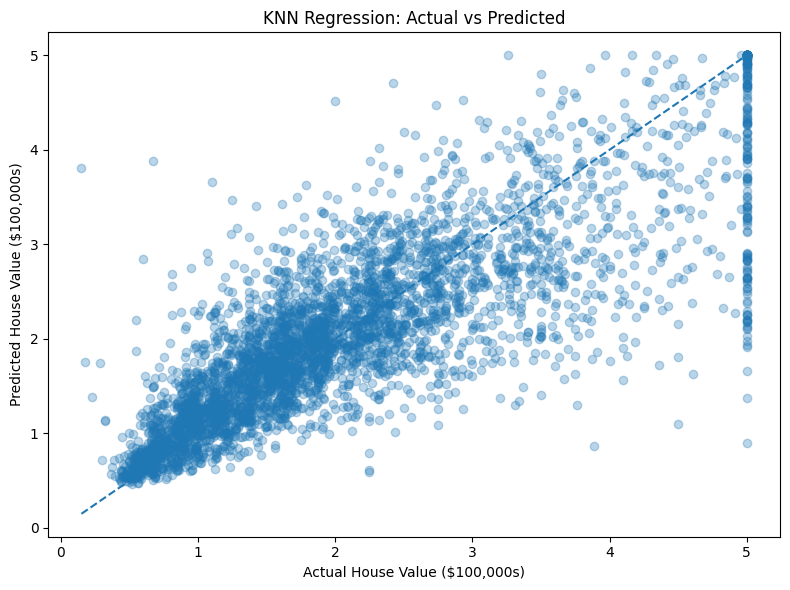

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual House Value ($100,000s)")
plt.ylabel("Predicted House Value ($100,000s)")
plt.title("KNN Regression: Actual vs Predicted")
plt.tight_layout()
plt.show()

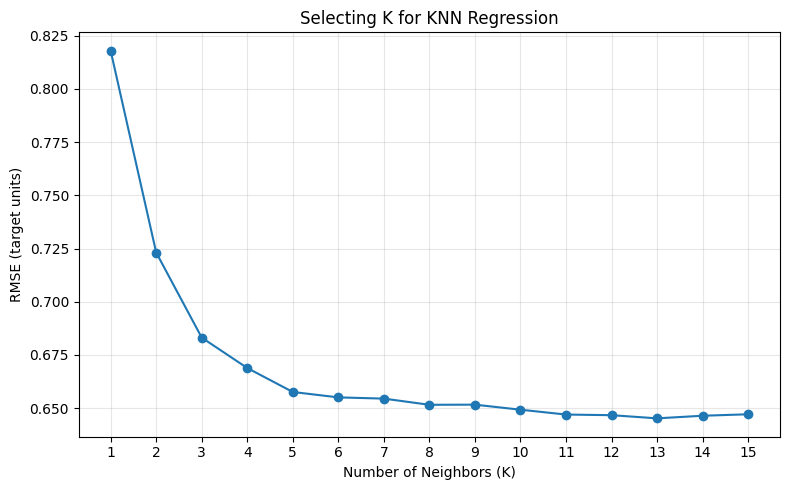

Best K in this comparison: 13


In [10]:
k_values = range(1, 16)
rmse_values = []

for k in k_values:
    model = KNeighborsRegressor(
        n_neighbors=k,
        weights="uniform",
        metric="euclidean"
    )

    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)

    rmse_values.append(
        np.sqrt(mean_squared_error(y_test, predictions))
    )

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), rmse_values, marker="o")

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("RMSE (target units)")
plt.title("Selecting K for KNN Regression")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_k = list(k_values)[np.argmin(rmse_values)]
print("Best K in this comparison:", best_k)